---

# HoloMine Property Price Prediction - XLM-RoBERTa Late Fusion

*Notebook end-to-end untuk regresi harga properti dari teks dengan domain-adaptive pretraining, XLM-RoBERTa, TF-IDF, fitur terstruktur hasil ekstraksi teks, dan leakage-safe stacking.*

---

## HoloMine Task 2 Team Notebook

- Workflow: team submission
- Primary model: XLM-RoBERTa Large
- Ensemble: TF-IDF Ridge + extracted-feature CatBoost + late-fusion stacker

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Validation and Feature Extraction**](#3)
4. [**Text Preprocessing and Token Budget**](#4)
5. [**Domain-Adaptive MLM Pretraining**](#5)
6. [**XLM-RoBERTa Regression Cross-Validation**](#6)
7. [**TF-IDF Regression Branch**](#7)
8. [**Structured CatBoost Branch**](#8)
9. [**Late Fusion and Stacking**](#9)
10. [**Diagnostics and Submission**](#10)
11. [**Artifact Packaging**](#11)

---

# Introduction <a name="1"></a>

---

## Overview

*HoloMine Property Price Prediction From Sales Description - Task 2 adalah task regresi NLP. Model hanya menerima `id` dan `text`, sedangkan `listPrice` tersedia pada training set sebagai target. Karena deskripsi listing memuat bahasa natural sekaligus sinyal numerik seperti luas, jumlah kamar, tahun, acreage, dan nilai uang, pendekatan ini memisahkan representasi bahasa dan fitur terstruktur sebelum menggabungkannya pada tahap akhir.*

## Aim

*Notebook ini membangun pipeline yang dapat langsung dijalankan pada satu GPU NVIDIA RTX 5090 di Vast.ai. Pipeline melakukan domain-adaptive masked-language-model pretraining pada corpus listing, fine-tuning XLM-RoBERTa Large untuk regresi, membangun dua branch tambahan, menghasilkan out-of-fold predictions yang konsisten, kemudian melakukan late fusion tanpa menggunakan target validation secara langsung pada base learner.*

## Metric

***Mean Absolute Error (MAE)** adalah metrik resmi kompetisi dan mengukur rata-rata selisih absolut antara harga aktual dan prediksi. Walaupun semua branch utama dilatih pada `log1p(listPrice)` untuk menstabilkan heavy tail, pemilihan model dan laporan performa utama tetap menggunakan MAE setelah prediksi dikembalikan ke skala harga asli.*

$$\mathrm{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

## Dataset

*Data kompetisi dibaca dari folder `data/` pada project root. Notebook juga memeriksa `/workspace/data` agar sesuai dengan pola mount Vast.ai.*

*Training set berisi 14,640 listing dan test set berisi 3,659 listing pada snapshot proyek yang digunakan untuk menyusun notebook ini. Notebook tidak mengandalkan angka tersebut untuk eksekusi; seluruh ukuran dataset dibaca ulang saat runtime.*

**Attributes**

1. `id`: identifier unik listing.
2. `text`: sales description dan informasi properti dalam bentuk teks.

**Target**

`listPrice`: harga listing yang harus diprediksi dan hanya tersedia pada `train.csv`.

## Approach: XLM-RoBERTa + Extracted Structured Features + Late Fusion

*Branch pertama menggunakan XLM-RoBERTa Large. Sebelum supervised fine-tuning, model menjalani domain-adaptive masked-language-model training pada teks listing agar representasinya menyesuaikan jargon real-estate dan pola numerik di corpus. Branch kedua menggunakan word dan character TF-IDF dengan Ridge regression, sedangkan branch ketiga mengekstrak informasi seperti bedroom, bathroom, square footage, acreage, year, garage, currency mentions, dan keyword properti untuk CatBoost.*

*Ketiga branch menggunakan fold yang sama. Setiap baris training menerima prediksi hanya dari model yang tidak dilatih pada baris tersebut. Prediksi OOF menjadi meta-features untuk stacker, sementara test prediction diperoleh dari rata-rata model antarfold.*

```text
Raw listing text
    |
    +-- Domain-adapted XLM-R Large -> OOF/test log-price
    |
    +-- Word + char TF-IDF + Ridge -> OOF/test log-price
    |
    +-- Regex/keyword extraction + CatBoost -> OOF/test log-price
             |
             +------ leakage-safe late fusion ------> final listPrice
```

*MLM dapat menggunakan train dan test text karena tidak mengakses `listPrice`. Jika aturan kompetisi atau kebutuhan evaluasi internal mengharuskan domain adaptation yang benar-benar inductive, `USE_TEST_FOR_MLM` dapat diubah menjadi `False`.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook ini ditujukan untuk image Vast.ai yang sudah memiliki PyTorch dengan build CUDA yang kompatibel dengan RTX 5090. Sel pertama memeriksa GPU dan sel instalasi tidak mengganti PyTorch secara otomatis agar wheel CUDA bawaan instance tidak rusak. Untuk menjalankan ulang dari checkpoint yang sudah ada, biarkan `FORCE_RETRAIN = False`.

In [1]:
!nvidia-smi

Sun Sep 20 09:49:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.95.05              Driver Version: 580.95.05      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        On  |   00000000:01:00.0 Off |                  N/A |
| 55%   68C    P1            499W /  500W |    6872MiB /  32607MiB |     97%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs all libraries used in this notebook. PyTorch sengaja tidak di-install ulang; gunakan template Vast.ai dengan PyTorch/CUDA yang sudah mengenali RTX 5090.

In [2]:
%pip install -q -U "transformers>=4.48,<5" "datasets>=3,<5" "accelerate>=1,<2" sentencepiece "scikit-learn>=1.5,<2" "scipy>=1.13,<2" "pandas>=2.2,<3" "numpy>=1.26,<3" "matplotlib>=3.8,<4" "catboost>=1.2,<2" "joblib>=1.4,<2" "pyarrow>=17,<25"

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Sel ini memusatkan seluruh import yang digunakan sepanjang notebook sehingga dependency mudah diaudit dan tidak tersebar di fungsi-fungsi berikutnya.

In [3]:
import gc
import hashlib
import json
import math
import os
import platform
import random
import re
import shutil
import time
import warnings
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from catboost import CatBoostRegressor
from datasets import Dataset
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
from transformers import (
    AutoModelForMaskedLM,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorForLanguageModeling,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
)

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

## Seed Everything

Semua sumber randomness utama diberi seed yang sama. CuDNN dibuat deterministic jika tersedia, sementara TF32 tetap diaktifkan pada GPU modern untuk mempercepat matrix multiplication.

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(42)

if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

## Settings

Semua path, hyperparameter, switch training, dan batas resource dipusatkan di `Settings`. Default disusun konservatif untuk XLM-RoBERTa Large pada RTX 5090 32 GB: sequence length 256, BF16 bila tersedia, gradient checkpointing, dan effective batch size yang diperbesar melalui gradient accumulation.

In [5]:
class Settings:
    SEED = 42
    RUN_NAME = "xlmr_late_fusion_v1"

    BASE_MODEL = "FacebookAI/xlm-roberta-large"
    MAX_LENGTH = 256
    N_FOLDS = 5

    USE_TEST_FOR_MLM = True
    RUN_MLM = True
    RUN_XLM = True
    RUN_TFIDF = True
    RUN_TABULAR = True
    RUN_STACKING = True
    FORCE_RETRAIN = False

    MLM_EPOCHS = 2.0
    MLM_LR = 1e-5
    MLM_BATCH_SIZE = 8
    MLM_GRAD_ACCUM = 4
    MLM_MASK_PROB = 0.15

    FT_EPOCHS = 4.0
    FT_LR = 2e-5
    FT_WEIGHT_DECAY = 0.01
    FT_BATCH_SIZE = 8
    FT_EVAL_BATCH_SIZE = 16
    FT_GRAD_ACCUM = 4
    EARLY_STOPPING_PATIENCE = 1

    TFIDF_WORD_MAX_FEATURES = 80000
    TFIDF_CHAR_MAX_FEATURES = 80000
    TFIDF_ALPHA = 10.0

    CAT_ITERATIONS = 1200
    CAT_DEPTH = 7
    CAT_LR = 0.03
    CAT_L2 = 5.0
    CAT_EARLY_STOPPING = 100

    META_ITERATIONS = 800
    META_DEPTH = 4
    META_LR = 0.025
    META_L2 = 8.0

    NUM_WORKERS = min(8, os.cpu_count() or 2)
    PACKAGE_MODELS = False

    DATA_CANDIDATES = [
        Path.cwd() / "data",
        Path.cwd().parent / "data",
        Path("/workspace/data"),
    ]

    PROJECT_ROOT = Path.cwd()
    OUTPUT_DIR = PROJECT_ROOT / "outputs" / RUN_NAME
    MODEL_DIR = OUTPUT_DIR / "models"
    OOF_DIR = OUTPUT_DIR / "oof_preds"
    LOG_DIR = OUTPUT_DIR / "logs"
    FIG_DIR = OUTPUT_DIR / "figures"
    SUBMISSION_DIR = OUTPUT_DIR / "submissions"


CFG = Settings()
for directory in [CFG.OUTPUT_DIR, CFG.MODEL_DIR, CFG.OOF_DIR, CFG.LOG_DIR, CFG.FIG_DIR, CFG.SUBMISSION_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

CFG.USE_BF16 = bool(torch.cuda.is_available() and torch.cuda.is_bf16_supported())
CFG.USE_FP16 = bool(torch.cuda.is_available() and not CFG.USE_BF16)
CFG.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", CFG.DEVICE)
print("BF16:", CFG.USE_BF16, "FP16:", CFG.USE_FP16)
print("Output:", CFG.OUTPUT_DIR)

Device: cuda
BF16: True FP16: False
Output: /workspace/outputs/xlmr_late_fusion_v1


## Load Dataset

Path loader mencari `train.csv`, `test.csv`, dan `sample_submission.csv` pada kandidat direktori yang lazim di project root dan Vast.ai. Tidak ada visualisasi pada tahap ini; sel hanya memuat data dan memvalidasi schema minimum.

In [6]:
def resolve_data_dir(candidates):
    required = {"train.csv", "test.csv", "sample_submission.csv"}
    searched = []
    for candidate in candidates:
        candidate = candidate.resolve()
        searched.append(str(candidate))
        if candidate.exists() and required.issubset({p.name for p in candidate.glob("*.csv")}):
            return candidate
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Pastikan folder data/ berisi train.csv, test.csv, dan sample_submission.csv. "
        + "Searched: " + " | ".join(searched)
    )


DATA_DIR = resolve_data_dir(CFG.DATA_CANDIDATES)
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

required_train = {"id", "text", "listPrice"}
required_test = {"id", "text"}
assert required_train.issubset(train_df.columns), f"Train columns: {train_df.columns.tolist()}"
assert required_test.issubset(test_df.columns), f"Test columns: {test_df.columns.tolist()}"
assert sample_submission.columns.tolist() == ["id", "listPrice"], sample_submission.columns.tolist()

print("DATA_DIR:", DATA_DIR)
print("train:", train_df.shape)
print("test :", test_df.shape)
print("sample:", sample_submission.shape)

DATA_DIR: /workspace/data
train: (14640, 3)
test : (3659, 2)
sample: (3659, 2)


---

# Data Validation and Feature Extraction <a name="3"></a>

---

Bagian ini memastikan target, ID, dan alignment submission valid sebelum proses training mahal dimulai. Fitur terstruktur kemudian diekstrak langsung dari `text`, sehingga branch tabular tetap mematuhi skema kompetisi yang hanya menyediakan teks.

## Integrity Checks

Pemeriksaan berikut menggagalkan eksekusi lebih awal jika ada target non-finite, ID ganda, overlap train-test, atau ID submission yang tidak dapat dipetakan ke test set.

In [7]:
assert train_df["id"].notna().all() and test_df["id"].notna().all()
assert train_df["id"].is_unique and test_df["id"].is_unique
assert set(train_df["id"]).isdisjoint(set(test_df["id"]))
assert np.isfinite(train_df["listPrice"].to_numpy(dtype=float)).all()
assert (train_df["listPrice"] >= 0).all()
assert set(sample_submission["id"]) == set(test_df["id"])

summary = pd.DataFrame(
    {
        "split": ["train", "test", "sample_submission"],
        "rows": [len(train_df), len(test_df), len(sample_submission)],
        "missing_cells": [int(train_df.isna().sum().sum()), int(test_df.isna().sum().sum()), int(sample_submission.isna().sum().sum())],
        "unique_ids": [train_df["id"].nunique(), test_df["id"].nunique(), sample_submission["id"].nunique()],
    }
)
display(summary)

,split,rows,missing_cells,unique_ids
0,train,14640,0,14640
1,test,3659,0,3659
2,sample_submission,3659,0,3659


#### Insights

> Training dan test harus mempunyai ID yang unik dan disjoint. Submission dibangun melalui mapping `id`, bukan dengan asumsi bahwa urutan baris `test.csv` selalu identik dengan `sample_submission.csv`.

## Target and Shared Folds

Target disimpan dalam dua representasi: harga asli untuk evaluasi MAE dan `log1p` untuk supervised training. Semua branch menggunakan indeks fold yang sama agar OOF prediction dapat disejajarkan tanpa ambiguity pada tahap stacking.

In [8]:
y_raw = train_df["listPrice"].to_numpy(dtype=np.float64)
y_log = np.log1p(y_raw).astype(np.float32)

kf = KFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
fold_ids = np.full(len(train_df), -1, dtype=np.int8)
fold_splits = []
for fold, (train_idx, val_idx) in enumerate(kf.split(train_df)):
    fold_ids[val_idx] = fold
    fold_splits.append((train_idx, val_idx))

assert (fold_ids >= 0).all()
train_df["fold"] = fold_ids

stats = train_df["listPrice"].describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.995]).to_frame("listPrice")
display(stats)
display(train_df.groupby("fold")["listPrice"].agg(["count", "median", "mean", "max"]))

,listPrice
count,1.464000e+04
mean,8.390729e+05
std,1.912897e+06
min,1.000000e+00
50%,4.999000e+05
90%,1.449000e+06
95%,2.300000e+06
99%,6.561000e+06
99.5%,1.086100e+07
max,8.000000e+07


,count,median,mean,max
fold,,,,
0,2928,509975.0,867667.505123,38500000.0
1,2928,499000.0,875248.037568,80000000.0
2,2928,499999.0,800317.853825,54580000.0
3,2928,499000.0,819761.758197,40000000.0
4,2928,499999.0,832369.438866,35000000.0


#### Insights

> `log1p` dipakai sebagai target optimisasi untuk mengurangi dominasi listing berharga sangat tinggi, tetapi kompetisi dinilai pada MAE harga asli. Oleh karena itu seluruh branch selalu menyimpan prediksi log dan raw secara bersamaan.

## Structured Feature Extractor

Extractor berikut memindahkan sinyal eksplisit dari teks ke fitur numerik dan binary. Ia mempertahankan informasi yang relevan terhadap valuasi properti tanpa memakai target: text length, jumlah digit, monetary mentions, bedrooms, bathrooms, area, acreage, year, garage, stories, dan kelompok keyword properti.

In [9]:
NUMBER_WORDS = {
    "zero": 0, "one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6,
    "seven": 7, "eight": 8, "nine": 9, "ten": 10, "eleven": 11, "twelve": 12,
}
NUM = r"(?:\d+(?:\.\d+)?|" + "|".join(NUMBER_WORDS) + r")"


def to_num(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return np.nan
    value = str(value).lower().strip()
    try:
        return float(value)
    except ValueError:
        return float(NUMBER_WORDS.get(value, np.nan))


def first_match(patterns, text, flags=re.I):
    for pattern in patterns:
        match = re.search(pattern, text, flags)
        if match:
            return to_num(match.group(1))
    return np.nan


def extract_features(text):
    text = str(text)
    low = text.lower()

    bedrooms = first_match([
        rf"\b({NUM})\s*(?:bed(?:room)?s?|br)\b",
        rf"\b({NUM})[- ]bed(?:room)?\b",
    ], low)
    bathrooms = first_match([
        rf"\b({NUM})\s*(?:full\s+)?bath(?:room)?s?\b",
        rf"\b({NUM})[- ]bath(?:room)?\b",
    ], low)
    half_baths = first_match([rf"\b({NUM})\s*half\s*bath(?:room)?s?\b"], low)

    sqft_mentions = []
    area_pattern = r"\b(\d{1,3}(?:,\s*\d{3})+|\d+(?:\.\d+)?)\s*(?:sq\.?\s*ft\.?|sqft|square[- ]?foot|square\s+feet|sf)\b"
    for match in re.finditer(area_pattern, low, re.I):
        try:
            value = float(re.sub(r"[,\s]", "", match.group(1)))
        except ValueError:
            continue
        context = low[max(0, match.start() - 70): min(len(low), match.end() + 70)]
        sqft_mentions.append((value, context))

    sqft_first = sqft_mentions[0][0] if sqft_mentions else np.nan
    sqft_min = min((value for value, _ in sqft_mentions), default=np.nan)
    sqft_max = max((value for value, _ in sqft_mentions), default=np.nan)

    lot_terms = ("lot", "parcel", "land", "site", "assemblage", "acre", "barn", "shop", "greenhouse", "warehouse")
    home_terms = ("home", "house", "residence", "living", "interior", "apartment", "condo", "townhome", "townhouse")
    building_values = []
    lot_values = []
    for value, context in sqft_mentions:
        has_lot = any(term in context for term in lot_terms)
        has_home = any(term in context for term in home_terms)
        if has_home and not has_lot:
            building_values.append(value)
        if has_lot and not has_home:
            lot_values.append(value)

    sqft = building_values[0] if building_values else sqft_first
    sqft_lot = lot_values[0] if lot_values else np.nan

    acres = np.nan
    fraction = re.search(r"\b(\d+)\s*/\s*(\d+)\s*(?:acre|acres)\b", low)
    if fraction and float(fraction.group(2)) != 0:
        acres = float(fraction.group(1)) / float(fraction.group(2))
    if np.isnan(acres):
        acreage = re.search(r"\b([\d,]+(?:\.\d+)?)\s*(?:\+/-\s*)?(?:acre|acres)\b", low)
        if acreage:
            try:
                acres = float(acreage.group(1).replace(",", ""))
            except ValueError:
                pass

    year_built = np.nan
    for pattern in [
        r"\bbuilt\s+(?:in\s+)?((?:18|19|20)\d{2})\b",
        r"\b(?:circa|c\.)\s*((?:18|19|20)\d{2})\b",
        r"\b((?:18|19|20)\d{2})\s+(?:home|house|bungalow|colonial|ranch|construction)\b",
    ]:
        match = re.search(pattern, low)
        if match:
            year_built = float(match.group(1))
            break

    year_renovated = np.nan
    for pattern in [
        r"\b(?:renovated|remodeled|updated)\s+(?:in\s+)?((?:19|20)\d{2})\b",
        r"\b((?:19|20)\d{2})\s+(?:renovation|renovated|remodel|remodeled)\b",
    ]:
        match = re.search(pattern, low)
        if match:
            year_renovated = float(match.group(1))
            break

    garage_cars = first_match([
        rf"\b({NUM})[- ]car\s+garage\b",
        rf"\bgarage\s+(?:for\s+)?({NUM})\s+cars?\b",
    ], low)
    stories = first_match([rf"\b({NUM})[- ]stor(?:y|ies)\b"], low)

    money = []
    for match in re.finditer(r"\$\s*(\d{1,3}(?:,\s*\d{3})+|\d+(?:\.\d+)?)\s*([kKmM](?![A-Za-z]))?", text):
        try:
            value = float(re.sub(r"[,\s]", "", match.group(1)))
            if match.group(2):
                value *= 1000 if match.group(2).lower() == "k" else 1_000_000
            money.append(value)
        except ValueError:
            pass

    features = {
        "char_len": len(text),
        "word_count": len(re.findall(r"\b\w+\b", text)),
        "digit_count": sum(char.isdigit() for char in text),
        "number_token_count": len(re.findall(r"\b\d+(?:\.\d+)?\b", text)),
        "currency_count": len(money),
        "currency_max": max(money) if money else np.nan,
        "redacted_count": len(re.findall(r"\[Redacted Entity\]", text, re.I)),
        "bedrooms": bedrooms,
        "bathrooms": bathrooms,
        "half_baths": half_baths,
        "sqft": sqft,
        "sqft_first": sqft_first,
        "sqft_min": sqft_min,
        "sqft_max": sqft_max,
        "sqft_lot": sqft_lot,
        "acres": acres,
        "year_built": year_built,
        "year_renovated": year_renovated,
        "garage_cars": garage_cars,
        "stories": stories,
    }

    keyword_groups = {
        "pool": ["pool", "swimming pool"],
        "basement": ["basement", "cellar"],
        "waterfront": ["waterfront", "lakefront", "oceanfront", "riverfront"],
        "condo": ["condo", "condominium"],
        "townhouse": ["townhouse", "townhome"],
        "multifamily": ["multi-family", "multifamily", "two-family", "2-family", "duplex", "triplex", "fourplex"],
        "commercial": ["commercial", "retail", "office space"],
        "land": ["vacant lot", "vacant land", "buildable lot", "acreage", "parcel of land"],
        "fixer": ["fixer", "as-is", "as is", "needs renovation", "major renovation", "tlc", "handyman"],
        "renovated": ["renovated", "remodeled", "updated", "move-in ready", "move in ready"],
        "new_construction": ["new construction", "brand new", "newly built", "to be built"],
        "luxury": ["luxury", "luxurious", "prestigious", "exquisite", "exceptional", "penthouse"],
        "garage": ["garage"],
        "fireplace": ["fireplace"],
        "hoa": ["hoa", "homeowners association"],
        "investment": ["investment", "investor", "income-producing", "rental income"],
        "foreclosure": ["foreclosure", "bank owned", "reo"],
        "auction": ["auction"],
        "zoning": ["zoned", "zoning"],
        "manhattan": ["manhattan"],
        "central_park": ["central park"],
    }
    for name, words in keyword_groups.items():
        features[f"kw_{name}"] = int(any(word in low for word in words))

    return features


def extract_frame(series):
    frame = pd.DataFrame([extract_features(value) for value in series], index=series.index)
    for column in list(frame.columns):
        if frame[column].isna().any():
            frame[f"{column}_missing"] = frame[column].isna().astype(np.int8)
    for column in ["currency_max", "sqft", "sqft_first", "sqft_min", "sqft_max", "sqft_lot", "acres"]:
        if column in frame.columns:
            frame[f"log1p_{column}"] = np.log1p(frame[column].clip(lower=0))
    return frame.replace([np.inf, -np.inf], np.nan)

## Extract Train and Test Features

Ekstraksi dijalankan sekali dan hasilnya disimpan sebagai CSV agar rerun tidak perlu mengulang regex parsing. Cache dibatalkan ketika `FORCE_RETRAIN = True`.

In [10]:
structured_train_path = CFG.OUTPUT_DIR / "structured_train.csv"
structured_test_path = CFG.OUTPUT_DIR / "structured_test.csv"

if structured_train_path.exists() and structured_test_path.exists() and not CFG.FORCE_RETRAIN:
    structured_train = pd.read_csv(structured_train_path)
    structured_test = pd.read_csv(structured_test_path)
else:
    structured_train = extract_frame(train_df["text"].fillna(""))
    structured_test = extract_frame(test_df["text"].fillna(""))
    structured_train.to_csv(structured_train_path, index=False)
    structured_test.to_csv(structured_test_path, index=False)

assert structured_train.columns.tolist() == structured_test.columns.tolist()
print("Structured feature matrix:", structured_train.shape, structured_test.shape)
display(structured_train.head())

Structured feature matrix: (14640, 62) (3659, 62)


,char_len,word_count,digit_count,number_token_count,currency_count,currency_max,redacted_count,bedrooms,bathrooms,half_baths,...,year_renovated_missing,garage_cars_missing,stories_missing,log1p_currency_max,log1p_sqft,log1p_sqft_first,log1p_sqft_min,log1p_sqft_max,log1p_sqft_lot,log1p_acres
0,1511,240,0,0,0,NaN,2,NaN,NaN,NaN,...,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,936,146,1,1,0,NaN,0,1.0,NaN,NaN,...,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,149,25,5,1,0,NaN,0,NaN,NaN,NaN,...,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,296,48,0,0,0,NaN,0,NaN,NaN,NaN,...,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,886,144,0,0,0,NaN,0,NaN,NaN,NaN,...,1,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Insights

> Structured features berasal sepenuhnya dari `text`. Missing indicators dipertahankan karena ketiadaan penyebutan atribut tertentu juga dapat menjadi sinyal, sedangkan log transforms memberi skala yang lebih stabil untuk nilai seperti area dan monetary mentions.

---

# Text Preprocessing and Token Budget <a name="4"></a>

---

Pipeline teks hanya melakukan normalisasi ringan. Angka, simbol mata uang, unit, dan redaction marker tidak dihapus. Thousands separator pada pola numerik dinormalisasi agar magnitude lebih mudah dibaca tokenizer, sementara whitespace berlebih dipadatkan.

## Numeric-Preserving Cleaning

Cleaning sengaja tidak melakukan stemming, stopword removal, lowercasing paksa, atau penghapusan punctuation secara agresif karena XLM-R sudah mempunyai tokenizer subword sendiri dan numeric/currency cues merupakan bagian penting dari task.

In [11]:
def clean_listing_text(text):
    text = str(text).replace("\r", " ").replace("\n", " ")
    text = re.sub(r"(?<=\d),\s*(?=\d{3}(?:\D|$))", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


train_texts = train_df["text"].fillna("").map(clean_listing_text).tolist()
test_texts = test_df["text"].fillna("").map(clean_listing_text).tolist()

print(train_texts[0][:700])

Nestled in the heart of Randolph, [Redacted Entity] offers a wonderful blend of small-town charm, everyday convenience, and comfortable living. This inviting property sits along a quiet, well-traveled street close to local shops, schools, dining, and community amenities, while still maintaining the peaceful, hometown feel Randolph is known for. From the moment you arrive, the home's curb appeal sets a welcoming tone, reflecting classic character and warmth that makes it easy to imagine coming home at the end of the day. Inside, the layout balances functionality with comfort, offering flexible spaces suited for relaxing, entertaining, or working from home. Natural light flows through the livi


#### Insights

> Cleaning ini mempertahankan isi semantik listing dan hanya menormalkan format yang dapat memecah angka. Branch TF-IDF dan XLM-R menggunakan representasi teks yang sama agar perbedaan performa terutama berasal dari model, bukan dari pipeline preprocessing yang tidak sebanding.

## GPU and Tokenizer Readiness

Sebelum model besar dimuat, notebook memeriksa nama GPU, compute capability, arsitektur yang dikenali build PyTorch, dan kemampuan BF16. Pada RTX 5090, BF16 digunakan bila build PyTorch mendukungnya. Tokenizer kemudian dipakai untuk mengukur coverage sequence length 256 pada corpus aktual.

In [12]:
if not torch.cuda.is_available():
    raise RuntimeError("GPU CUDA tidak terdeteksi. Notebook ini ditujukan untuk Vast.ai dengan RTX 5090.")

gpu_name = torch.cuda.get_device_name(0)
gpu_capability = torch.cuda.get_device_capability(0)
arch_list = torch.cuda.get_arch_list()

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA runtime reported by PyTorch:", torch.version.cuda)
print("GPU:", gpu_name)
print("Compute capability:", gpu_capability)
print("Torch arch list:", arch_list)
print("BF16 supported:", torch.cuda.is_bf16_supported())

if "5090" in gpu_name and not any("120" in arch for arch in arch_list):
    print("WARNING: RTX 5090 terdeteksi tetapi build PyTorch tidak menampilkan sm_120. Gunakan image Vast.ai dengan PyTorch/CUDA Blackwell-compatible.")

Python: 3.12.14
PyTorch: 2.11.0+cu128
CUDA runtime reported by PyTorch: 12.8
GPU: NVIDIA GeForce RTX 5090
Compute capability: (12, 0)
Torch arch list: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
BF16 supported: True


In [13]:
tokenizer = AutoTokenizer.from_pretrained(CFG.BASE_MODEL, use_fast=True)

def estimate_token_lengths(texts, batch_size=512):
    lengths = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        encoded = tokenizer(batch, add_special_tokens=True, truncation=False, return_length=True)
        lengths.extend(encoded["length"])
    return np.asarray(lengths)


all_token_lengths = estimate_token_lengths(train_texts + test_texts)
coverage = float((all_token_lengths <= CFG.MAX_LENGTH).mean())
print(pd.Series(all_token_lengths).describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
print(f"Coverage at max_length={CFG.MAX_LENGTH}: {coverage:.2%}")

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (668 > 512). Running this sequence through the model will result in indexing errors


count    18299.000000
mean       236.093557
std        137.306052
min         14.000000
50%        211.000000
90%        422.000000
95%        485.000000
99%        690.000000
max       1188.000000
dtype: float64
Coverage at max_length=256: 65.33%


#### Insights

> Sequence length 256 adalah default yang seimbang untuk XLM-R Large pada 32 GB VRAM. Jika coverage aktual terlalu rendah, `MAX_LENGTH` dapat dinaikkan ke 384 atau 512 dengan mengurangi `FT_BATCH_SIZE`; jika OOM terjadi, kurangi batch size terlebih dahulu dan pertahankan effective batch melalui gradient accumulation.

---

# Domain-Adaptive MLM Pretraining <a name="5"></a>

---

Domain-adaptive pretraining melanjutkan masked-language modeling XLM-R pada corpus listing sebelum regresi. Tahap ini menggunakan teks tanpa label dan menyimpan checkpoint dengan format Hugging Face `save_pretrained`, sehingga backbone yang sama dapat langsung dipakai oleh regression head.

## Prepare MLM Corpus

Secara default corpus menggabungkan train dan test text sesuai plan. Tidak ada `listPrice` yang digunakan pada tahap ini. Untuk evaluasi internal yang sepenuhnya inductive, set `USE_TEST_FOR_MLM = False` sebelum menjalankan section ini.

In [14]:
mlm_texts = train_texts + test_texts if CFG.USE_TEST_FOR_MLM else train_texts
mlm_dataset = Dataset.from_dict({"text": mlm_texts})


def tokenize_mlm(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=CFG.MAX_LENGTH,
        return_special_tokens_mask=True,
    )


mlm_tokenized = mlm_dataset.map(
    tokenize_mlm,
    batched=True,
    remove_columns=["text"],
    desc="Tokenizing MLM corpus",
)

mlm_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=True,
    mlm_probability=CFG.MLM_MASK_PROB,
    pad_to_multiple_of=8,
)

print("MLM samples:", len(mlm_tokenized))

Tokenizing MLM corpus:   0%|          | 0/18299 [00:00<?, ? examples/s]

MLM samples: 18299


## Run or Reuse MLM Checkpoint

Checkpoint disimpan di `models/xlmr_domain_mlm`. Jika direktori tersebut sudah berisi `config.json` dan `FORCE_RETRAIN` bernilai `False`, training dilewati. Mekanisme ini penting untuk instance spot atau sesi Vast.ai yang terputus.

In [15]:
mlm_model_dir = CFG.MODEL_DIR / "xlmr_domain_mlm"
mlm_ready = (mlm_model_dir / "config.json").exists()

if CFG.RUN_MLM and (CFG.FORCE_RETRAIN or not mlm_ready):
    seed_everything(CFG.SEED)
    mlm_model = AutoModelForMaskedLM.from_pretrained(CFG.BASE_MODEL)
    mlm_model.gradient_checkpointing_enable()

    mlm_args = TrainingArguments(
        output_dir=str(CFG.MODEL_DIR / "mlm_checkpoints"),
        overwrite_output_dir=CFG.FORCE_RETRAIN,
        num_train_epochs=CFG.MLM_EPOCHS,
        learning_rate=CFG.MLM_LR,
        weight_decay=CFG.FT_WEIGHT_DECAY,
        per_device_train_batch_size=CFG.MLM_BATCH_SIZE,
        gradient_accumulation_steps=CFG.MLM_GRAD_ACCUM,
        lr_scheduler_type="linear",
        warmup_ratio=0.05,
        logging_steps=50,
        save_strategy="epoch",
        save_total_limit=1,
        bf16=CFG.USE_BF16,
        fp16=CFG.USE_FP16,
        tf32=True,
        gradient_checkpointing=True,
        optim="adamw_torch_fused",
        dataloader_num_workers=CFG.NUM_WORKERS,
        report_to="none",
        seed=CFG.SEED,
        data_seed=CFG.SEED,
    )

    mlm_trainer = Trainer(
        model=mlm_model,
        args=mlm_args,
        train_dataset=mlm_tokenized,
        data_collator=mlm_collator,
        processing_class=tokenizer,
    )
    mlm_result = mlm_trainer.train()
    mlm_trainer.save_model(str(mlm_model_dir))
    tokenizer.save_pretrained(str(mlm_model_dir))

    with open(CFG.LOG_DIR / "mlm_metrics.json", "w", encoding="utf-8") as handle:
        json.dump(mlm_result.metrics, handle, indent=2)

    del mlm_trainer, mlm_model
    gc.collect()
    torch.cuda.empty_cache()
else:
    print("MLM checkpoint reused:", mlm_model_dir)

assert (mlm_model_dir / "config.json").exists(), "MLM checkpoint belum tersedia. Jalankan RUN_MLM=True."

model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

Some weights of the model checkpoint at FacebookAI/xlm-roberta-large were not used when initializing XLMRobertaForMaskedLM: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing XLMRobertaForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing XLMRobertaForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Step,Training Loss
50,1.236400
100,1.185800
150,1.164000
200,1.145000
250,1.121300
300,1.122400
350,1.103400
400,1.105600
450,1.099000
500,1.051900


#### Insights

> Domain-adapted checkpoint menjadi satu-satunya starting point untuk seluruh supervised fold. Karena tahap ini tidak memakai target, satu checkpoint dapat dipakai ulang pada semua fold dan menghindari pengulangan MLM yang sangat mahal.

---

# XLM-RoBERTa Regression Cross-Validation <a name="6"></a>

---

Fine-tuning memakai lima fold yang sama dengan branch lain. Loss regresi dihitung pada `log1p(listPrice)`, sedangkan callback metric mengubah output kembali ke harga asli dan memonitor MAE raw untuk memilih checkpoint terbaik tiap fold.

## Dataset and Metric Helpers

Dynamic padding digunakan melalui `DataCollatorWithPadding` agar batch tidak selalu dipaksa ke 256 token. Truncation tetap dibatasi oleh `MAX_LENGTH`, sehingga memory usage lebih rendah dibanding fixed padding tanpa mengubah token budget maksimum.

In [16]:
def make_supervised_dataset(texts, labels=None):
    payload = {"text": list(texts)}
    if labels is not None:
        payload["labels"] = np.asarray(labels, dtype=np.float32)
    dataset = Dataset.from_dict(payload)

    def tokenize_batch(batch):
        return tokenizer(batch["text"], truncation=True, max_length=CFG.MAX_LENGTH)

    return dataset.map(tokenize_batch, batched=True, remove_columns=["text"])


def regression_metrics(eval_pred):
    predictions, labels = eval_pred
    pred_log = np.asarray(predictions).reshape(-1)
    true_log = np.asarray(labels).reshape(-1)
    pred_raw = np.maximum(np.expm1(pred_log), 0.0)
    true_raw = np.maximum(np.expm1(true_log), 0.0)
    return {
        "mae_raw": mean_absolute_error(true_raw, pred_raw),
        "mae_log": mean_absolute_error(true_log, pred_log),
    }


def load_regression_model():
    model = AutoModelForSequenceClassification.from_pretrained(
        str(mlm_model_dir),
        num_labels=1,
        problem_type="regression",
    )
    model.config.use_cache = False
    model.gradient_checkpointing_enable()
    return model


data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)

## Train Five XLM-R Folds

Setiap fold menyimpan `val_predictions.csv`, `test_predictions.csv`, metrics JSON, dan model final. Jika semua file prediksi sudah ada, rerun akan langsung memuat cache tanpa memuat model ke GPU.

In [20]:
    train_dataset_fold = make_supervised_dataset(
        [train_texts[i] for i in train_idx],
        y_log[train_idx],
    )
    val_dataset_fold = make_supervised_dataset(
        [train_texts[i] for i in val_idx],
        y_log[val_idx],
    )

    rescue_ckpt = fold_dir / "checkpoints" / "checkpoint-366"
    is_rescued_fold = fold == 4 and (rescue_ckpt / "model.safetensors").exists()

    if is_rescued_fold:
        print(f"Fold {fold}: RESCUE dari {rescue_ckpt}")
        model = AutoModelForSequenceClassification.from_pretrained(
            str(rescue_ckpt),
            num_labels=1,
            problem_type="regression",
        )
        model.config.use_cache = False
        model.gradient_checkpointing_enable()
        epochs_to_train = max(CFG.FT_EPOCHS - 1, 1)
    else:
        model = load_regression_model()
        epochs_to_train = CFG.FT_EPOCHS

    training_args = TrainingArguments(
        output_dir=str(fold_dir / ("checkpoints_rescued" if is_rescued_fold else "checkpoints")),
        overwrite_output_dir=CFG.FORCE_RETRAIN,
        num_train_epochs=epochs_to_train,
        learning_rate=CFG.FT_LR,
        weight_decay=CFG.FT_WEIGHT_DECAY,
        per_device_train_batch_size=CFG.FT_BATCH_SIZE,
        per_device_eval_batch_size=CFG.FT_EVAL_BATCH_SIZE,
        gradient_accumulation_steps=CFG.FT_GRAD_ACCUM,
        lr_scheduler_type="linear",
        warmup_ratio=0.08,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="steps",
        logging_steps=50,
        load_best_model_at_end=True,
        metric_for_best_model="mae_raw",
        greater_is_better=False,
        save_total_limit=1,
        save_only_model=True,
        bf16=CFG.USE_BF16,
        fp16=CFG.USE_FP16,
        tf32=True,
        gradient_checkpointing=True,
        optim="adamw_torch_fused",
        dataloader_num_workers=CFG.NUM_WORKERS,
        report_to="none",
        seed=CFG.SEED + fold,
        data_seed=CFG.SEED + fold,
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset_fold,
        eval_dataset=val_dataset_fold,
        data_collator=data_collator,
        processing_class=tokenizer,
        compute_metrics=regression_metrics,
        callbacks=[EarlyStoppingCallback(
            early_stopping_patience=CFG.EARLY_STOPPING_PATIENCE
        )],
    )

    train_result = trainer.train()

Map:   0%|          | 0/11712 [00:00<?, ? examples/s]

Map:   0%|          | 0/2928 [00:00<?, ? examples/s]

Fold 4: RESCUE dari /workspace/outputs/xlmr_late_fusion_v1/models/xlmr_fold_4/checkpoints/checkpoint-366


Epoch,Training Loss,Validation Loss,Mae Raw,Mae Log
1,0.610700,0.465732,392395.906250,0.492845
2,0.394500,0.321165,354655.031250,0.409061
3,0.234900,0.352920,404335.125000,0.453377


In [22]:
# ============================================================
# FINALIZE XLM-R FOLD 4 RESCUE + REBUILD OOF/TEST FROM CACHE
# ============================================================

# Fold 4 baru saja selesai rescue training.
# Ambil prediction validation + test dari model hasil training tersebut.
print(f"Finalizing rescued fold {fold}...")

val_output = trainer.predict(val_dataset_fold)
test_output = trainer.predict(test_dataset_xlm)

val_pred_log = (
    np.asarray(val_output.predictions)
    .reshape(-1)
    .astype(np.float32)
)

test_pred_log = (
    np.asarray(test_output.predictions)
    .reshape(-1)
    .astype(np.float32)
)

# ------------------------------------------------------------
# Save prediction fold 4 supaya setelah ini benar-benar cached
# ------------------------------------------------------------

fold_dir = CFG.MODEL_DIR / f"xlmr_fold_{fold}"

val_pred_path = fold_dir / "val_predictions.csv"
test_pred_path = fold_dir / "test_predictions.csv"
metrics_path = fold_dir / "metrics.json"

fold_metrics = {
    "fold": int(fold),
    "val_mae_raw": float(
        mean_absolute_error(
            y_raw[val_idx],
            np.maximum(np.expm1(val_pred_log), 0.0),
        )
    ),
    "val_mae_log": float(
        mean_absolute_error(
            y_log[val_idx],
            val_pred_log,
        )
    ),
    "best_metric": (
        float(trainer.state.best_metric)
        if trainer.state.best_metric is not None
        else None
    ),
    "train_runtime": float(
        train_result.metrics.get("train_runtime", np.nan)
    ),
    "rescued": True,
}

pd.DataFrame({
    "id": train_df.iloc[val_idx]["id"].to_numpy(),
    "fold": fold,
    "y_true": y_raw[val_idx],
    "pred_log": val_pred_log,
    "pred_raw": np.maximum(np.expm1(val_pred_log), 0.0),
}).to_csv(val_pred_path, index=False)

pd.DataFrame({
    "id": test_df["id"].to_numpy(),
    "pred_log": test_pred_log,
    "pred_raw": np.maximum(np.expm1(test_pred_log), 0.0),
}).to_csv(test_pred_path, index=False)

with open(metrics_path, "w", encoding="utf-8") as handle:
    json.dump(fold_metrics, handle, indent=2)

# Simpan final/best model fold 4 juga
best_model_dir = fold_dir / "best_model"
trainer.save_model(str(best_model_dir))
tokenizer.save_pretrained(str(best_model_dir))

print(f"Fold {fold} predictions + model saved.")


# ============================================================
# REBUILD SEMUA OOF + TEST DARI CACHE FOLD 0-4
# ============================================================

oof_xlm_log = np.full(
    len(train_df),
    np.nan,
    dtype=np.float32,
)

test_xlm_fold_log = []
xlm_fold_metrics = []

for f, (_, v_idx) in enumerate(fold_splits):

    f_dir = CFG.MODEL_DIR / f"xlmr_fold_{f}"

    f_val_path = f_dir / "val_predictions.csv"
    f_test_path = f_dir / "test_predictions.csv"
    f_metrics_path = f_dir / "metrics.json"

    if not f_val_path.exists():
        raise FileNotFoundError(
            f"Missing validation cache fold {f}: {f_val_path}"
        )

    if not f_test_path.exists():
        raise FileNotFoundError(
            f"Missing test cache fold {f}: {f_test_path}"
        )

    val_cache = pd.read_csv(f_val_path)
    test_cache = pd.read_csv(f_test_path)

    val_fold_pred = val_cache["pred_log"].to_numpy(
        dtype=np.float32
    )

    test_fold_pred = test_cache["pred_log"].to_numpy(
        dtype=np.float32
    )

    if len(val_fold_pred) != len(v_idx):
        raise RuntimeError(
            f"Fold {f}: validation prediction length mismatch: "
            f"{len(val_fold_pred)} != {len(v_idx)}"
        )

    if len(test_fold_pred) != len(test_df):
        raise RuntimeError(
            f"Fold {f}: test prediction length mismatch: "
            f"{len(test_fold_pred)} != {len(test_df)}"
        )

    oof_xlm_log[v_idx] = val_fold_pred
    test_xlm_fold_log.append(test_fold_pred)

    if f_metrics_path.exists():
        with open(f_metrics_path, encoding="utf-8") as handle:
            xlm_fold_metrics.append(json.load(handle))

    print(f"Fold {f}: cache loaded")


# ============================================================
# FINAL XLM-R PREDICTIONS
# ============================================================

assert np.isfinite(oof_xlm_log).all(), (
    "OOF XLM-R masih mengandung NaN/Inf"
)

test_xlm_log = np.mean(
    np.vstack(test_xlm_fold_log),
    axis=0,
).astype(np.float32)

assert np.isfinite(test_xlm_log).all(), (
    "Test XLM-R masih mengandung NaN/Inf"
)

oof_xlm_raw = np.maximum(
    np.expm1(oof_xlm_log),
    0.0,
)

test_xlm_raw = np.maximum(
    np.expm1(test_xlm_log),
    0.0,
)

xlm_oof_mae = mean_absolute_error(
    y_raw,
    oof_xlm_raw,
)

print()
print("XLM-R OOF raw MAE:", xlm_oof_mae)


# ============================================================
# SAVE FINAL OOF + TEST
# ============================================================

CFG.OOF_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

pd.DataFrame({
    "id": train_df["id"],
    "fold": fold_ids,
    "y_true": y_raw,
    "pred_log": oof_xlm_log,
    "pred_raw": oof_xlm_raw,
    "abs_error": np.abs(
        y_raw - oof_xlm_raw
    ),
}).to_csv(
    CFG.OOF_DIR / "xlmr_oof.csv",
    index=False,
)

pd.DataFrame({
    "id": test_df["id"],
    "pred_log": test_xlm_log,
    "pred_raw": test_xlm_raw,
}).to_csv(
    CFG.OOF_DIR / "xlmr_test.csv",
    index=False,
)

print(
    "Saved:",
    CFG.OOF_DIR / "xlmr_oof.csv"
)
print(
    "Saved:",
    CFG.OOF_DIR / "xlmr_test.csv"
)

display(
    pd.DataFrame(xlm_fold_metrics)
)

Finalizing rescued fold 4...


Fold 4 predictions + model saved.
Fold 0: cache loaded
Fold 1: cache loaded
Fold 2: cache loaded
Fold 3: cache loaded
Fold 4: cache loaded

XLM-R OOF raw MAE: 400257.2975563925
Saved: /workspace/outputs/xlmr_late_fusion_v1/oof_preds/xlmr_oof.csv
Saved: /workspace/outputs/xlmr_late_fusion_v1/oof_preds/xlmr_test.csv


,fold,val_mae_raw,val_mae_log,best_metric,train_runtime,rescued
0,0,410509.010657,0.474949,410509.03125,863.6665,NaN
1,1,499335.388899,0.574155,499335.34375,437.2781,NaN
2,2,362388.540307,0.455623,362388.53125,595.8902,NaN
3,3,374398.538704,0.433188,374398.50000,443.9192,NaN
4,4,354655.009216,0.409061,354655.03125,289.9811,True


#### Insights

> OOF XLM-R prediction adalah fitur utama untuk stacker. Averaging test predictions dari lima fold mengurangi variance tanpa memerlukan satu training full-data tambahan, sementara setiap OOF row tetap berasal dari model yang tidak melihat target row tersebut.

---

# TF-IDF Regression Branch <a name="7"></a>

---

Branch sparse text berfungsi sebagai model yang sangat berbeda dari transformer. Word bigrams menangkap frasa listing, sementara character n-grams tahan terhadap variasi ejaan, format angka, singkatan, dan token lokal yang mungkin dipotong berbeda oleh SentencePiece.

## Five-Fold Word + Character TF-IDF Ridge

Vectorizer selalu di-fit hanya pada training portion setiap fold. Ini mencegah vocabulary dan IDF validation masuk ke training. Target Ridge menggunakan log-price agar sejalan dengan XLM-R dan structured branch.

In [23]:
def run_tfidf_branch():
    oof_log = np.full(len(train_df), np.nan, dtype=np.float32)
    test_fold_log = []
    rows = []

    for fold, (train_idx, val_idx) in enumerate(fold_splits):
        fold_dir = CFG.MODEL_DIR / f"tfidf_fold_{fold}"
        fold_dir.mkdir(parents=True, exist_ok=True)
        val_path = fold_dir / "val_predictions.csv"
        test_path = fold_dir / "test_predictions.csv"
        model_path = fold_dir / "ridge.joblib"
        word_path = fold_dir / "word_vectorizer.joblib"
        char_path = fold_dir / "char_vectorizer.joblib"

        cache_ready = val_path.exists() and test_path.exists()
        if cache_ready and not CFG.FORCE_RETRAIN:
            val_cache = pd.read_csv(val_path)
            test_cache = pd.read_csv(test_path)
            val_pred_log = val_cache["pred_log"].to_numpy(dtype=np.float32)
            test_pred_log = test_cache["pred_log"].to_numpy(dtype=np.float32)
        else:
            if not CFG.RUN_TFIDF:
                raise RuntimeError(f"TF-IDF fold {fold} cache tidak ada dan RUN_TFIDF=False")

            train_text_fold = [train_texts[i] for i in train_idx]
            val_text_fold = [train_texts[i] for i in val_idx]

            word_vectorizer = TfidfVectorizer(
                analyzer="word",
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.995,
                max_features=CFG.TFIDF_WORD_MAX_FEATURES,
                sublinear_tf=True,
                strip_accents="unicode",
                dtype=np.float32,
            )
            char_vectorizer = TfidfVectorizer(
                analyzer="char_wb",
                ngram_range=(3, 5),
                min_df=3,
                max_features=CFG.TFIDF_CHAR_MAX_FEATURES,
                sublinear_tf=True,
                dtype=np.float32,
            )

            xw_train = word_vectorizer.fit_transform(train_text_fold)
            xw_val = word_vectorizer.transform(val_text_fold)
            xw_test = word_vectorizer.transform(test_texts)

            xc_train = char_vectorizer.fit_transform(train_text_fold)
            xc_val = char_vectorizer.transform(val_text_fold)
            xc_test = char_vectorizer.transform(test_texts)

            x_train = hstack([xw_train, xc_train], format="csr")
            x_val = hstack([xw_val, xc_val], format="csr")
            x_test = hstack([xw_test, xc_test], format="csr")

            model = Ridge(alpha=CFG.TFIDF_ALPHA, solver="lsqr", tol=1e-3)
            model.fit(x_train, y_log[train_idx])
            val_pred_log = model.predict(x_val).astype(np.float32)
            test_pred_log = model.predict(x_test).astype(np.float32)

            joblib.dump(model, model_path)
            joblib.dump(word_vectorizer, word_path)
            joblib.dump(char_vectorizer, char_path)

            pd.DataFrame({"id": train_df.iloc[val_idx]["id"], "pred_log": val_pred_log}).to_csv(val_path, index=False)
            pd.DataFrame({"id": test_df["id"], "pred_log": test_pred_log}).to_csv(test_path, index=False)

            del xw_train, xw_val, xw_test, xc_train, xc_val, xc_test, x_train, x_val, x_test
            del word_vectorizer, char_vectorizer, model
            gc.collect()

        oof_log[val_idx] = val_pred_log
        test_fold_log.append(test_pred_log)
        fold_mae = mean_absolute_error(y_raw[val_idx], np.maximum(np.expm1(val_pred_log), 0.0))
        rows.append({"fold": fold, "mae_raw": fold_mae})
        print(f"TF-IDF fold {fold}: MAE={fold_mae:,.2f}")

    return oof_log, np.mean(np.vstack(test_fold_log), axis=0).astype(np.float32), pd.DataFrame(rows)


oof_tfidf_log, test_tfidf_log, tfidf_metrics = run_tfidf_branch()
oof_tfidf_raw = np.maximum(np.expm1(oof_tfidf_log), 0.0)
test_tfidf_raw = np.maximum(np.expm1(test_tfidf_log), 0.0)

print("TF-IDF OOF raw MAE:", mean_absolute_error(y_raw, oof_tfidf_raw))
display(tfidf_metrics)

TF-IDF fold 0: MAE=407,813.45
TF-IDF fold 1: MAE=412,091.49
TF-IDF fold 2: MAE=356,767.39
TF-IDF fold 3: MAE=361,252.60
TF-IDF fold 4: MAE=380,875.01
TF-IDF OOF raw MAE: 383759.98681640625


,fold,mae_raw
0,0,407813.446947
1,1,412091.489633
2,2,356767.388603
3,3,361252.600585
4,4,380875.008315


In [24]:
pd.DataFrame({
    "id": train_df["id"],
    "fold": fold_ids,
    "y_true": y_raw,
    "pred_log": oof_tfidf_log,
    "pred_raw": oof_tfidf_raw,
    "abs_error": np.abs(y_raw - oof_tfidf_raw),
}).to_csv(CFG.OOF_DIR / "tfidf_oof.csv", index=False)

pd.DataFrame({
    "id": test_df["id"],
    "pred_log": test_tfidf_log,
    "pred_raw": test_tfidf_raw,
}).to_csv(CFG.OOF_DIR / "tfidf_test.csv", index=False)

#### Insights

> TF-IDF tetap dipertahankan meskipun XLM-R biasanya lebih ekspresif, karena error pattern sparse model dapat berbeda. Nilai ensemble datang dari complementarity antarmodel, bukan hanya dari memilih satu model dengan MAE individual terendah.

---

# Structured CatBoost Branch <a name="8"></a>

---

Branch ini memodelkan fitur hasil ekstraksi tanpa menggabungkannya langsung ke token sequence. Pemisahan tersebut merupakan late-fusion design: text encoder dan numeric/keyword encoder mengembangkan prediksi secara independen sebelum meta-model mempelajari bobot kombinasi.

## Five-Fold CatBoost on Extracted Features

CatBoost menerima missing values secara native, sehingga nilai numerik yang tidak disebutkan dalam listing tetap sebagai `NaN` dan didampingi missing indicators. Early stopping memonitor validation set pada setiap fold.

In [25]:
def run_tabular_branch():
    x_train = structured_train.copy()
    x_test = structured_test.copy()
    oof_log = np.full(len(train_df), np.nan, dtype=np.float32)
    test_fold_log = []
    rows = []

    for fold, (train_idx, val_idx) in enumerate(fold_splits):
        fold_dir = CFG.MODEL_DIR / f"tabular_fold_{fold}"
        fold_dir.mkdir(parents=True, exist_ok=True)
        val_path = fold_dir / "val_predictions.csv"
        test_path = fold_dir / "test_predictions.csv"
        model_path = fold_dir / "catboost.cbm"

        cache_ready = val_path.exists() and test_path.exists() and model_path.exists()
        if cache_ready and not CFG.FORCE_RETRAIN:
            val_pred_log = pd.read_csv(val_path)["pred_log"].to_numpy(dtype=np.float32)
            test_pred_log = pd.read_csv(test_path)["pred_log"].to_numpy(dtype=np.float32)
        else:
            if not CFG.RUN_TABULAR:
                raise RuntimeError(f"Tabular fold {fold} cache tidak ada dan RUN_TABULAR=False")

            model = CatBoostRegressor(
                iterations=CFG.CAT_ITERATIONS,
                depth=CFG.CAT_DEPTH,
                learning_rate=CFG.CAT_LR,
                loss_function="MAE",
                eval_metric="MAE",
                l2_leaf_reg=CFG.CAT_L2,
                random_seed=CFG.SEED + fold,
                random_strength=0.5,
                verbose=100,
                allow_writing_files=False,
                thread_count=-1,
            )
            model.fit(
                x_train.iloc[train_idx],
                y_log[train_idx],
                eval_set=(x_train.iloc[val_idx], y_log[val_idx]),
                use_best_model=True,
                early_stopping_rounds=CFG.CAT_EARLY_STOPPING,
            )

            val_pred_log = model.predict(x_train.iloc[val_idx]).astype(np.float32)
            test_pred_log = model.predict(x_test).astype(np.float32)
            model.save_model(str(model_path))

            pd.DataFrame({"id": train_df.iloc[val_idx]["id"], "pred_log": val_pred_log}).to_csv(val_path, index=False)
            pd.DataFrame({"id": test_df["id"], "pred_log": test_pred_log}).to_csv(test_path, index=False)
            del model
            gc.collect()

        oof_log[val_idx] = val_pred_log
        test_fold_log.append(test_pred_log)
        fold_mae = mean_absolute_error(y_raw[val_idx], np.maximum(np.expm1(val_pred_log), 0.0))
        rows.append({"fold": fold, "mae_raw": fold_mae})
        print(f"Tabular fold {fold}: MAE={fold_mae:,.2f}")

    return oof_log, np.mean(np.vstack(test_fold_log), axis=0).astype(np.float32), pd.DataFrame(rows)


oof_tab_log, test_tab_log, tab_metrics = run_tabular_branch()
oof_tab_raw = np.maximum(np.expm1(oof_tab_log), 0.0)
test_tab_raw = np.maximum(np.expm1(test_tab_log), 0.0)

print("Structured OOF raw MAE:", mean_absolute_error(y_raw, oof_tab_raw))
display(tab_metrics)

0:	learn: 0.7000322	test: 0.7028962	best: 0.7028962 (0)	total: 49ms	remaining: 58.8s
100:	learn: 0.5671513	test: 0.5832355	best: 0.5832355 (100)	total: 226ms	remaining: 2.46s
200:	learn: 0.5408781	test: 0.5660529	best: 0.5660529 (200)	total: 402ms	remaining: 2s
300:	learn: 0.5264038	test: 0.5606126	best: 0.5606020 (299)	total: 578ms	remaining: 1.73s
400:	learn: 0.5144109	test: 0.5565958	best: 0.5565958 (400)	total: 754ms	remaining: 1.5s
500:	learn: 0.5036760	test: 0.5538911	best: 0.5538489 (499)	total: 925ms	remaining: 1.29s
600:	learn: 0.4962440	test: 0.5525750	best: 0.5525743 (599)	total: 1.09s	remaining: 1.09s
700:	learn: 0.4907219	test: 0.5517216	best: 0.5516816 (697)	total: 1.26s	remaining: 900ms
800:	learn: 0.4862007	test: 0.5512678	best: 0.5512653 (797)	total: 1.43s	remaining: 713ms
900:	learn: 0.4820261	test: 0.5507643	best: 0.5507213 (891)	total: 1.6s	remaining: 532ms
1000:	learn: 0.4776406	test: 0.5500314	best: 0.5500252 (998)	total: 1.77s	remaining: 352ms
1100:	learn: 0.4744

,fold,mae_raw
0,0,441988.386879
1,1,454981.777244
2,2,408540.940079
3,3,417855.382514
4,4,428652.094877


In [26]:
pd.DataFrame({
    "id": train_df["id"],
    "fold": fold_ids,
    "y_true": y_raw,
    "pred_log": oof_tab_log,
    "pred_raw": oof_tab_raw,
    "abs_error": np.abs(y_raw - oof_tab_raw),
}).to_csv(CFG.OOF_DIR / "tabular_oof.csv", index=False)

pd.DataFrame({
    "id": test_df["id"],
    "pred_log": test_tab_log,
    "pred_raw": test_tab_raw,
}).to_csv(CFG.OOF_DIR / "tabular_test.csv", index=False)

#### Insights

> Structured branch memaksa model melihat magnitude yang dapat sulit dipelajari hanya dari subword tokens. Jika MAE branch ini tidak mengalahkan transformer, ia tetap dapat membantu stacker selama residual-nya tidak identik dengan residual XLM-R.

---

# Late Fusion and Stacking <a name="9"></a>

---

Meta-features terdiri dari tiga OOF log predictions. Evaluasi stacker dilakukan dengan CV kedua di atas OOF matrix, bukan dengan menilai model pada meta-data yang sama dengan data fit-nya. Setelah kandidat stacker dipilih berdasarkan nested OOF raw MAE, model final di-fit pada seluruh OOF matrix dan diterapkan pada averaged test meta-features.

## Build Meta-Features and Check Complementarity

Sebelum fitting stacker, notebook membandingkan MAE tiap branch dan korelasi residual. Korelasi residual yang lebih rendah menunjukkan peluang ensemble yang lebih besar.

In [27]:
meta_train = np.column_stack([oof_xlm_log, oof_tfidf_log, oof_tab_log]).astype(np.float32)
meta_test = np.column_stack([test_xlm_log, test_tfidf_log, test_tab_log]).astype(np.float32)
meta_columns = ["xlmr_log", "tfidf_log", "tabular_log"]

branch_raw = {
    "XLM-R": oof_xlm_raw,
    "TF-IDF": oof_tfidf_raw,
    "Structured": oof_tab_raw,
}
branch_scores = pd.DataFrame([
    {"model": name, "oof_mae_raw": mean_absolute_error(y_raw, pred)}
    for name, pred in branch_raw.items()
]).sort_values("oof_mae_raw")

display(branch_scores)

residual_frame = pd.DataFrame({name: y_raw - pred for name, pred in branch_raw.items()})
display(residual_frame.corr())

,model,oof_mae_raw
1,TF-IDF,383759.986816
0,XLM-R,400257.297556
2,Structured,430403.716318


,XLM-R,TF-IDF,Structured
XLM-R,1.000000,0.961663,0.876878
TF-IDF,0.961663,1.000000,0.921397
Structured,0.876878,0.921397,1.000000


## Nested Meta-Model Evaluation

Dua meta-model ringan dibandingkan: Ridge pada log-space dan CatBoost pada tiga base predictions. Keduanya dievaluasi pada fold meta-level yang terpisah. Model dengan raw-price MAE lebih rendah dipilih otomatis.

In [28]:
def build_meta_model(kind, seed):
    if kind == "ridge":
        return Ridge(alpha=1.0)
    if kind == "catboost":
        return CatBoostRegressor(
            iterations=CFG.META_ITERATIONS,
            depth=CFG.META_DEPTH,
            learning_rate=CFG.META_LR,
            loss_function="MAE",
            l2_leaf_reg=CFG.META_L2,
            random_seed=seed,
            verbose=False,
            allow_writing_files=False,
            thread_count=-1,
        )
    raise ValueError(kind)


meta_cv = KFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED + 777)
meta_candidates = ["ridge", "catboost"]
meta_oof_predictions = {}
meta_results = []

for kind in meta_candidates:
    pred_log = np.full(len(train_df), np.nan, dtype=np.float32)
    for meta_fold, (meta_train_idx, meta_val_idx) in enumerate(meta_cv.split(meta_train)):
        model = build_meta_model(kind, CFG.SEED + meta_fold)
        model.fit(meta_train[meta_train_idx], y_log[meta_train_idx])
        pred_log[meta_val_idx] = model.predict(meta_train[meta_val_idx]).astype(np.float32)

    pred_raw = np.maximum(np.expm1(pred_log), 0.0)
    mae_raw = mean_absolute_error(y_raw, pred_raw)
    mae_log = mean_absolute_error(y_log, pred_log)
    meta_oof_predictions[kind] = pred_log
    meta_results.append({"meta_model": kind, "nested_oof_mae_raw": mae_raw, "nested_oof_mae_log": mae_log})

meta_results = pd.DataFrame(meta_results).sort_values("nested_oof_mae_raw").reset_index(drop=True)
display(meta_results)

best_meta_kind = meta_results.loc[0, "meta_model"]
print("Selected meta-model:", best_meta_kind)

,meta_model,nested_oof_mae_raw,nested_oof_mae_log
0,catboost,344281.917972,0.406148
1,ridge,351486.899176,0.413151


Selected meta-model: catboost


## Fit Final Stacker and Predict Test

Model final hanya di-fit setelah meta-model dipilih. Training input-nya tetap terdiri dari OOF base predictions, sedangkan test input menggunakan rata-rata prediction dari base models across folds.

In [29]:
if not CFG.RUN_STACKING:
    raise RuntimeError("RUN_STACKING=False. Aktifkan stacking untuk membuat final prediction.")

final_meta_model = build_meta_model(best_meta_kind, CFG.SEED)
final_meta_model.fit(meta_train, y_log)
final_pred_log = final_meta_model.predict(meta_test).astype(np.float32)
final_pred_raw = np.maximum(np.expm1(final_pred_log), 0.0)

stack_oof_log = meta_oof_predictions[best_meta_kind]
stack_oof_raw = np.maximum(np.expm1(stack_oof_log), 0.0)
stack_oof_mae = mean_absolute_error(y_raw, stack_oof_raw)

if best_meta_kind == "catboost":
    final_meta_model.save_model(str(CFG.MODEL_DIR / "stacker_catboost.cbm"))
else:
    joblib.dump(final_meta_model, CFG.MODEL_DIR / "stacker_ridge.joblib")

pd.DataFrame({
    "id": train_df["id"],
    "fold": fold_ids,
    "y_true": y_raw,
    "oof_xlmr_log": oof_xlm_log,
    "oof_tfidf_log": oof_tfidf_log,
    "oof_tabular_log": oof_tab_log,
    "stack_pred_log": stack_oof_log,
    "stack_pred_raw": stack_oof_raw,
    "abs_error": np.abs(y_raw - stack_oof_raw),
}).to_csv(CFG.OOF_DIR / "stack_oof.csv", index=False)

print(f"Nested stack OOF raw MAE: {stack_oof_mae:,.2f}")

Nested stack OOF raw MAE: 344,281.92


#### Insights

> Skor stacker yang dilaporkan berasal dari meta-level OOF prediction. Ini lebih konservatif daripada melatih stacker pada seluruh OOF matrix lalu menghitung MAE pada matrix yang sama, yang akan menghasilkan estimasi terlalu optimistis.

---

# Diagnostics and Submission <a name="10"></a>

---

Bagian akhir membandingkan branch, memeriksa error pada segmen harga, menyimpan plot diagnostik, dan membuat file submission berdasarkan ID. Tidak ada clipping upper-tail secara default karena harga ekstrem adalah bagian sah dari metric competition.

## Model Comparison

Tabel ini menjadi ringkasan utama CV. Semua nilai MAE berada pada skala `listPrice` asli sehingga langsung sebanding dengan leaderboard metric.

In [30]:
comparison = pd.concat([
    branch_scores,
    pd.DataFrame([{"model": f"Stack ({best_meta_kind})", "oof_mae_raw": stack_oof_mae}]),
], ignore_index=True).sort_values("oof_mae_raw").reset_index(drop=True)
comparison.to_csv(CFG.LOG_DIR / "model_comparison.csv", index=False)
display(comparison)

,model,oof_mae_raw
0,Stack (catboost),344281.917972
1,TF-IDF,383759.986816
2,XLM-R,400257.297556
3,Structured,430403.716318


## Error by Price Segment

MAE keseluruhan dapat didominasi oleh upper tail. Decile diagnostics menunjukkan apakah ensemble hanya membaik pada listing umum atau juga mengurangi error untuk properti mahal.

In [31]:
error_df = pd.DataFrame({
    "y_true": y_raw,
    "pred": stack_oof_raw,
    "abs_error": np.abs(y_raw - stack_oof_raw),
})
error_df["price_decile"] = pd.qcut(error_df["y_true"].rank(method="first"), 10, labels=False) + 1
error_by_decile = error_df.groupby("price_decile").agg(
    n=("y_true", "size"),
    true_median=("y_true", "median"),
    pred_median=("pred", "median"),
    mae=("abs_error", "mean"),
).reset_index()
error_by_decile.to_csv(CFG.LOG_DIR / "error_by_price_decile.csv", index=False)
display(error_by_decile)

,price_decile,n,true_median,pred_median,mae
0,1,1464,94900.0,1.764911e+05,1.098485e+05
1,2,1464,209000.0,2.835638e+05,1.196924e+05
2,3,1464,299900.0,3.648955e+05,1.165381e+05
3,4,1464,385000.0,4.174527e+05,1.163846e+05
4,5,1464,459000.0,4.769569e+05,1.148798e+05
5,6,1464,549900.0,5.250433e+05,1.342516e+05
6,7,1464,651187.5,6.019188e+05,1.572499e+05
7,8,1464,799900.0,6.809670e+05,2.260579e+05
8,9,1464,1100000.0,8.209405e+05,4.110988e+05
9,10,1464,2300000.0,1.474600e+06,1.936818e+06


## Diagnostic Figures

Plot disimpan ke `figures/` agar dapat ditinjau setelah training selesai tanpa membuka ulang seluruh notebook state.

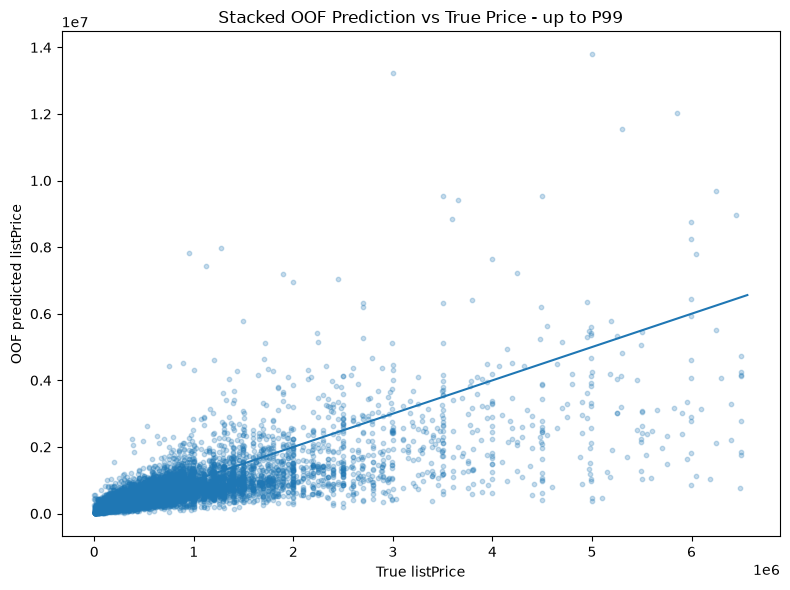

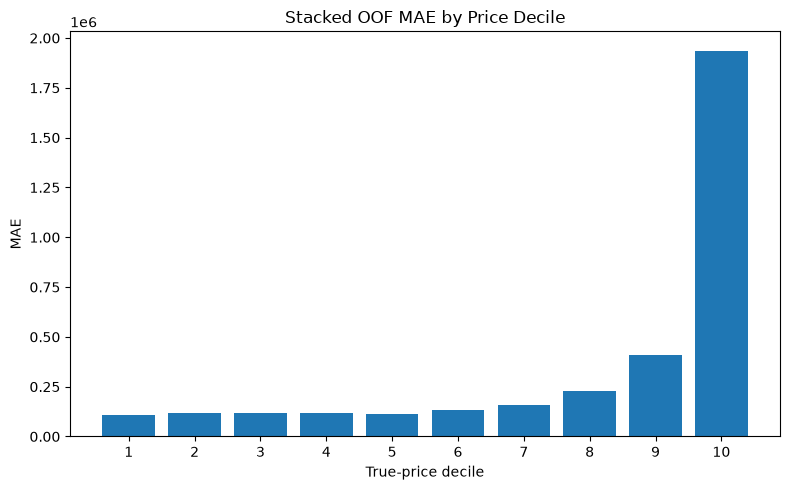

In [32]:
plt.figure(figsize=(8, 6))
plot_cap = np.quantile(y_raw, 0.99)
mask = y_raw <= plot_cap
plt.scatter(y_raw[mask], stack_oof_raw[mask], s=10, alpha=0.25)
plt.plot([0, plot_cap], [0, plot_cap], linewidth=1.5)
plt.xlabel("True listPrice")
plt.ylabel("OOF predicted listPrice")
plt.title("Stacked OOF Prediction vs True Price - up to P99")
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / "stack_pred_vs_true_p99.png", dpi=160)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(error_by_decile["price_decile"].astype(str), error_by_decile["mae"])
plt.xlabel("True-price decile")
plt.ylabel("MAE")
plt.title("Stacked OOF MAE by Price Decile")
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / "stack_mae_by_decile.png", dpi=160)
plt.show()

#### Insights

> Scatter plot menggunakan batas P99 hanya untuk keterbacaan visual; perhitungan MAE tetap memakai seluruh data, termasuk extreme prices. Decile table harus dibaca bersama overall MAE sebelum melakukan eksperimen tail calibration tambahan.

## Create Submission

Prediction dipetakan ke `sample_submission` berdasarkan `id`. Assertion memastikan semua ID mendapatkan prediksi finite dan non-negative sebelum file ditulis.

In [33]:
prediction_by_id = pd.Series(final_pred_raw, index=test_df["id"].to_numpy())
submission = sample_submission[["id"]].copy()
submission["listPrice"] = submission["id"].map(prediction_by_id)

assert submission["listPrice"].notna().all()
assert np.isfinite(submission["listPrice"]).all()
assert (submission["listPrice"] >= 0).all()

submission_path = CFG.SUBMISSION_DIR / f"submission_{CFG.RUN_NAME}.csv"
submission.to_csv(submission_path, index=False)

print("Saved:", submission_path)
display(submission.head())

Saved: /workspace/outputs/xlmr_late_fusion_v1/submissions/submission_xlmr_late_fusion_v1.csv


,id,listPrice
0,RE_015637,5.369278e+05
1,RE_005176,3.904542e+05
2,RE_013544,7.917012e+05
3,RE_016667,3.834744e+05
4,RE_011479,1.465843e+06


---

# Artifact Packaging <a name="11"></a>

---

Notebook menyimpan configuration, metrics, OOF files, figures, dan submission dalam satu run directory. Model XLM-R sangat besar, sehingga archive default tidak memasukkan checkpoint kecuali `PACKAGE_MODELS = True`.

## Save Run Configuration and Manifest

Manifest merekam versi library, GPU, hyperparameter utama, selected stacker, dan skor OOF sehingga eksperimen dapat dibandingkan tanpa bergantung pada state notebook.

In [34]:
run_manifest = {
    "run_name": CFG.RUN_NAME,
    "base_model": CFG.BASE_MODEL,
    "seed": CFG.SEED,
    "n_folds": CFG.N_FOLDS,
    "max_length": CFG.MAX_LENGTH,
    "use_test_for_mlm": CFG.USE_TEST_FOR_MLM,
    "mlm_epochs": CFG.MLM_EPOCHS,
    "ft_epochs": CFG.FT_EPOCHS,
    "ft_lr": CFG.FT_LR,
    "ft_batch_size": CFG.FT_BATCH_SIZE,
    "ft_grad_accum": CFG.FT_GRAD_ACCUM,
    "tfidf_alpha": CFG.TFIDF_ALPHA,
    "selected_meta_model": best_meta_kind,
    "stack_oof_mae_raw": float(stack_oof_mae),
    "gpu": gpu_name,
    "gpu_capability": list(gpu_capability),
    "torch_version": torch.__version__,
    "torch_cuda": torch.version.cuda,
}

with open(CFG.LOG_DIR / "run_manifest.json", "w", encoding="utf-8") as handle:
    json.dump(run_manifest, handle, indent=2)

print(json.dumps(run_manifest, indent=2))

{
  "run_name": "xlmr_late_fusion_v1",
  "base_model": "FacebookAI/xlm-roberta-large",
  "seed": 42,
  "n_folds": 5,
  "max_length": 256,
  "use_test_for_mlm": true,
  "mlm_epochs": 2.0,
  "ft_epochs": 4.0,
  "ft_lr": 2e-05,
  "ft_batch_size": 8,
  "ft_grad_accum": 4,
  "tfidf_alpha": 10.0,
  "selected_meta_model": "catboost",
  "stack_oof_mae_raw": 344281.9179723854,
  "gpu": "NVIDIA GeForce RTX 5090",
  "gpu_capability": [
    12,
    0
  ],
  "torch_version": "2.11.0+cu128",
  "torch_cuda": "12.8"
}


## Build `artifacts.zip`

Archive memasukkan logs, OOF predictions, figures, structured feature cache, dan submission. Checkpoint model hanya ditambahkan bila `PACKAGE_MODELS` diaktifkan karena lima XLM-R Large folds dapat menghasilkan archive berukuran banyak gigabyte.

In [35]:
archive_path = CFG.OUTPUT_DIR / "artifacts.zip"
include_roots = [CFG.OOF_DIR, CFG.LOG_DIR, CFG.FIG_DIR, CFG.SUBMISSION_DIR]
if CFG.PACKAGE_MODELS:
    include_roots.append(CFG.MODEL_DIR)

with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for root in include_roots:
        for file_path in root.rglob("*"):
            if file_path.is_file():
                archive.write(file_path, arcname=file_path.relative_to(CFG.OUTPUT_DIR))
    for feature_path in [structured_train_path, structured_test_path]:
        if feature_path.exists():
            archive.write(feature_path, arcname=feature_path.relative_to(CFG.OUTPUT_DIR))

print("Artifacts:", archive_path)
print("Size (MB):", archive_path.stat().st_size / (1024 ** 2))

Artifacts: /workspace/outputs/xlmr_late_fusion_v1/artifacts.zip
Size (MB): 1.860152244567871


#### Insights

> Pipeline selesai ketika `submission_*.csv`, `stack_oof.csv`, `model_comparison.csv`, dan `artifacts.zip` tersedia. Untuk eksperimen lanjutan, ubah satu kelompok hyperparameter pada `Settings`, gunakan `RUN_NAME` baru, dan pertahankan fold seed yang sama agar perbandingan OOF tetap fair.